# Figure 7: what the Saturn cross pathways explain across five datasets

Each Saturn fit of Figs. 2 to 6 pairs RNA with one other modality: ATAC in the LPC10 lesion section (Fig. 2, 3,425 spots) and
the melanoma section (Fig. 3, 1,997 spots), isoform usage in the mouse brain RT&T-MERFISH section (Fig. 4, 2,721 bins of
100 um), protein in the Sprox-seq tonsil section B1 (Fig. 5, 3,204 spots) and Hi-C compartments in the melanoma Hi-C
section (Fig. 6, 6,108 spots). Every pathway of a Saturn model is additive, so each fit splits into an own term (the modality's own axis) and a
cross term (the other modality's axis). Fig. 7 asks where and for which genes the cross term explains variance.

The notebook starts from the five saved fits, decomposes each per spot, tests every RNA gene for a cross term, checks that
the ATAC cross term of a gene is also present in its own cis chromatin, asks what absorbs the ATAC cross term, and looks at
the zones where rho_ATAC changes faster than rho_RNA. It draws panels b to j of Fig. 7 and Supplementary Figs. 12 to 15.

**Inputs:** the targets and saved models of Figs. 2 to 6, the RNA counts of each dataset, the ATAC counts of the two RNA+ATAC
datasets, chromVAR TF activity, cell-type composition and CODEX protein per spot (see the cells that read them).

**Conda env:** `spatialmultivelo`, CPU only. **Time:** about 12 min (the transect bootstraps and the rotation nulls take
most of it).

**Not covered:** Fig. 7a and Supplementary Fig. 12a compare Saturn with GASTON fitted to each modality alone (30 restarts
per modality); the GASTON baseline is not run here, so these two panels are not drawn.

## Setup

The cross-term analyses ran with `OMP_NUM_THREADS` unset, so the thread variables are removed before numpy and torch are
imported.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.pop(v, None)
import gzip, json
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.io import mmread
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

import saturn
from saturn import crossterm as CT, mechanism as MP, transition as TR
from saturn.annotate import gene_lengths
from saturn.theme import MODALITY, CMAP, ANCHOR, REFERENCE

saturn.theme.set_theme(7)
INK, GREY, SLATE, MIST = ANCHOR["ink"], REFERENCE, ANCHOR["slate"], ANCHOR["mist"]

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))
PUB = WORK / "published"
OUT = WORK / "results" / "fig7"; OUT.mkdir(parents=True, exist_ok=True)

## The five fits

Each fit is read from its saved targets (`targets_<dataset>.npz`: targets, coordinates, barcodes) and model weights
(`saturn_best.pt`), both made in the Fig. 2 to 6 notebooks. The axes are oriented as in those figures: each axis keeps the
sign of the axis stored with the figure (`axes.csv`, or the Fig. 5 spot table for Sprox-seq).

In [2]:
KEYS = ["lpc10", "melanoma", "merfish", "sprox", "hic"]
ATAC_KEYS = ["lpc10", "melanoma"]
FITS = {
    "lpc10": dict(ds="lpc10_fov", weights="lpc10_fov", X="ATAC", axes="lpc10_fov/axes.csv", cols=["d_RNA", "d_ATAC"]),
    "melanoma": dict(ds="melanoma_tissue", weights="melanoma_tissue", X="ATAC", axes="melanoma_tissue/axes.csv",
                     cols=["d_RNA", "d_ATAC"]),
    "merfish": dict(ds="rtt_merfish_s5_iso100_sv_pca_shrunk", weights="rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_lc0.3_weights",
                    X="Isoform", axes="rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_lc0.3/axes.csv", cols=["d_RNA", "d_Isoform"]),
    "sprox": dict(ds="sproxseq_B1_p46_dr", weights="sproxseq_B1_p46_dr", X="Protein", axes="sproxseq_B1_fig5/spots.csv",
                  cols=["rho_RNA", "rho_Protein"]),
    "hic": dict(ds="mel_hic_abins_dr50_51_rnadr", weights="mel_hic_abins_dr50_51_rnadr", X="HiC",
                axes="mel_hic_abins_dr50_51_rnadr/axes.csv", cols=["d_RNA", "d_HiC"]),
}
GTF = {"lpc10": WORK / "gencode.vM25.primary_chr.annotation.gtf", "merfish": WORK / "gencode.vM25.primary_chr.annotation.gtf",
       "melanoma": WORK / "gencode.v21.annotation.gtf", "sprox": WORK / "gencode.v21.annotation.gtf",
       "hic": WORK / "gencode.v21.annotation.gtf"}


def load_fit(key):
    """targets, barcodes, modality order and the saved model of one fit"""
    c = FITS[key]
    z = dict(np.load(PUB / f"targets_{c['ds']}.npz", allow_pickle=True))
    mods = [str(m) for m in z["modalities"]]
    model = saturn.load_model(str(PUB / c["weights"] / "saturn_best.pt"), [z[f"Y_{m}"].shape[1] for m in mods])
    return z, [str(b) for b in z["barcodes"]], mods, model


for k in KEYS:
    z, bc, mods, _ = load_fit(k)
    print(f"{k:9s} {len(bc):5d} spots  " + "  ".join(f"{m}: {z[f'Y_{m}'].shape[1]} components" for m in mods))

lpc10      3425 spots  RNA: 10 components  ATAC: 7 components
melanoma   1997 spots  RNA: 10 components  ATAC: 6 components
merfish    2721 spots  RNA: 10 components  Isoform: 10 components
sprox      3204 spots  RNA: 10 components  Protein: 10 components
hic        6108 spots  RNA: 10 components  HiC: 10 components


### RNA and ATAC counts

The gene tests use the RNA counts of each dataset at the spots of its fit. The LPC10 and melanoma RNA and ATAC AnnData were
made from the raw DBiT reads in the Fig. 2 and Fig. 3 notebooks and are read from `published/`. The MERFISH genes are
summed into the same 100 um bins as the isoform target (bins with at least 3 cells). Sprox-seq and the melanoma Hi-C section
use their 10x matrices.

In [3]:
_RNA, _ATAC = {}, {}


def read_10x(prefix):
    bcs = [l.strip() for l in gzip.open(f"{prefix}barcodes.tsv.gz", "rt")]
    feat = pd.read_csv(f"{prefix}features.tsv.gz", sep="\t", header=None)
    return sp.csr_matrix(mmread(f"{prefix}matrix.mtx.gz").T), pd.Index(bcs), np.array([str(v) for v in feat[1]])


def merfish_genes(sample=5, bin_um=100.0):
    """RT&T-MERFISH gene counts summed per bin; the bin code is the barcode of the isoform target"""
    a = ad.read_h5ad(WORK / "cellxgene_ISO_labels.h5ad")
    a = a[a.obs["sample"].astype(str) == str(sample)]
    iso = np.array([str(v).startswith("ENSMUST") for v in a.var_names])
    xy = a.obs[["global_x", "global_y"]].values.astype(float)
    key = np.floor(xy / bin_um).astype(np.int64); code = key[:, 0] * 1_000_000 + key[:, 1]
    uniq, inv, cnt = np.unique(code, return_inverse=True, return_counts=True); kb = np.where(cnt >= 3)[0]
    G = sp.csr_matrix((np.ones(len(inv)), (inv, np.arange(len(inv)))), shape=(len(uniq), len(inv)))[kb]
    Xg = sp.csr_matrix(G @ sp.csr_matrix(a.X)[:, np.where(~iso)[0]])
    return Xg, pd.Index([str(u) for u in uniq[kb]]), np.array([str(v) for v in a.var_names[~iso]])


def rna_counts(key, bc):
    """RNA counts (spots x genes, CSR) in the order of bc, and the gene names"""
    if key not in _RNA:
        if key in ATAC_KEYS:
            f = PUB / ("arcseq_LPC10S1_rna_adata.h5ad" if key == "lpc10" else "melanoma_rna.h5ad")
            A = ad.read_h5ad(f); X, rows, genes = sp.csr_matrix(A.X), pd.Index(A.obs_names.astype(str)), np.array(A.var_names.astype(str))
        elif key == "merfish":
            X, rows, genes = merfish_genes()
        else:
            X, rows, genes = read_10x(WORK / ("GSM9156294_B1_" if key == "sprox" else "SpHIC117_RNA_"))
        i = rows.get_indexer(pd.Index(bc))
        if (i < 0).any():
            raise ValueError(f"{key}: {int((i < 0).sum())} fit barcodes have no RNA row")
        _RNA[key] = (X[i], genes)
    return _RNA[key]


def atac_counts(key, bc):
    """ATAC peaks (LPC10) or 5 kb tiles (melanoma) for the spots in bc, and the region names"""
    if key not in _ATAC:
        if key == "melanoma":
            import hdf5plugin  # noqa: F401  (the tile matrix is stored with a compression filter)
        A = ad.read_h5ad(PUB / ("arcseq_LPC10S1_atac_adata.h5ad" if key == "lpc10" else "atac_snap.h5ad"))
        A.obs_names = A.obs_names.astype(str); _ATAC[key] = A
    A = _ATAC[key][pd.Index(bc)]
    return A.X, A.var_names

## Cross term per spot and per gene

For each fit, `saturn.crossterm.spot_decomposition` evaluates the model at every spot and returns both axes, their spatial
gradients (autograd through the isodepth networks, averaged over the 25 nearest spots), and the local cross gain of each
modality: how much the squared error of a spot drops when the cross term is used instead of held at its mean, over the
mean total sum of squares, averaged over the 25 nearest spots.

`gene_cross_test` fits every RNA gene detected in at least 5% of spots (log1p CP10k) on a hinge basis of rho_RNA (linear
plus 5 ReLU hinges at the 10 to 90% quantiles, the pathway family of Saturn), then adds the same basis of the other axis;
partial F test, Benjamini-Hochberg q. The B(rho_X) part of the full fit is the gene's cross profile.

For the two ATAC datasets, `cis_windows` sums each significant gene's accessibility within 50 kb of its TSS and
`cis_concordance` correlates the gene's cross profile with that window's cross profile, against the gene paired with a random
other gene's window (200 draws). `steepness_test` correlates each modality's local gain with the steepness ratio
log((|grad rho_X| / median) / (|grad rho_RNA| / median)), with a two-sided p against 200 rotations of the gain field.

In [4]:
def cross_term(key):
    c = FITS[key]; z, bc, mods, model = load_fit(key)
    iR, iX = mods.index("RNA"), mods.index(c["X"])
    d = saturn.decompose(model, z["coords_z"])[0]
    ref = pd.read_csv(PUB / c["axes"], index_col=0); ref.index = ref.index.astype(str); ref = ref.loc[bc, c["cols"]].values
    signs = [np.sign(np.corrcoef(d[:, i], ref[:, j])[0, 1]) for j, i in enumerate((iR, iX))]
    T, S0 = CT.spot_decomposition(model, z["coords_z"], z["coords"], [z[f"Y_{m}"] for m in mods], iR, iX, signs, knn=25)
    T.index = bc; T.to_csv(OUT / f"{key}_spots.csv")
    S = dict(key=key, dataset=c["ds"], X=c["X"], coupling=S0["coupling"], R2_RNA=S0["R2_RNA"], R2_X=S0["R2_X"])
    X, genes = rna_counts(key, bc)
    G, prof, genes = CT.gene_cross_test(X, genes, T.rho_RNA.values, T.rho_X.values, min_det=0.05)
    G.to_csv(OUT / f"{key}_genes.csv", index=False)
    np.savez_compressed(OUT / f"{key}_profiles.npz", genes=genes, prof=prof.astype(np.float32))
    S.update(n_genes=int(len(G)), n_cross_fdr05=int((G.q < 0.05).sum()))
    if c["X"] == "ATAC":
        sig = G.sort_index().q.values < 0.05                                   # tested-gene order
        A, regions = atac_counts(key, bc)
        keep, W, _ = CT.cis_windows(A, regions, genes[sig], GTF[key], window=50_000)
        cis, S["cis"] = CT.cis_concordance(prof, genes, W, keep, T.rho_RNA.values, T.rho_X.values, ndraw=200)
        cis.to_csv(OUT / f"{key}_cis.csv", index=False)
    T = pd.read_csv(OUT / f"{key}_spots.csv", index_col=0)
    S.update(CT.steepness_test(T, nrot=200))
    json.dump(S, open(OUT / f"{key}_summary.json", "w"), indent=1, default=float)


for k in KEYS:
    if not (OUT / f"{k}_summary.json").exists():
        cross_term(k)

SP = {k: pd.read_csv(OUT / f"{k}_spots.csv", index_col=0) for k in KEYS}
for T in SP.values():
    T.index = T.index.astype(str)
SUM = {k: json.load(open(OUT / f"{k}_summary.json")) for k in KEYS}
GEN = {k: pd.read_csv(OUT / f"{k}_genes.csv") for k in KEYS}
CIS = {k: pd.read_csv(OUT / f"{k}_cis.csv") for k in ATAC_KEYS}
pd.DataFrame({k: dict(R2_RNA=SUM[k]["R2_RNA"]["full"], R2_RNA_own=SUM[k]["R2_RNA"]["own_only"], R2_X=SUM[k]["R2_X"]["full"],
                      R2_X_own=SUM[k]["R2_X"]["own_only"], gain_RNA=SP[k].gain_RNA.mean(), gain_X=SP[k].gain_X.mean(),
                      genes_tested=len(GEN[k]), cross_genes=int(((GEN[k].q < 0.05) & (GEN[k].dR2_cross >= 0.01)).sum()))
              for k in KEYS}).T.round(3)

,R2_RNA,R2_RNA_own,R2_X,R2_X_own,gain_RNA,gain_X,genes_tested,cross_genes
lpc10,0.643,0.365,0.674,0.498,0.281,0.176,4476.0,812.0
melanoma,0.786,0.655,0.822,0.466,0.133,0.354,15347.0,5198.0
merfish,0.577,0.488,0.486,0.457,0.088,0.030,13374.0,5252.0
sprox,0.611,0.442,0.557,0.428,0.170,0.131,13100.0,3436.0
hic,0.204,0.160,0.587,0.542,0.044,0.045,6360.0,704.0


The main figure shows the three datasets with the largest cross term (mean local cross gain of RNA plus that of the other
modality); Supplementary Fig. 13 shows the other two.

In [5]:
mean_gain = {k: SP[k].gain_RNA.mean() + SP[k].gain_X.mean() for k in KEYS}
top3 = sorted(KEYS, key=lambda k: -mean_gain[k])[:3]
MAIN = [k for k in KEYS if k in top3]; REST = [k for k in KEYS if k not in top3]
print("main figure:", MAIN, " supplement:", REST)

main figure: ['lpc10', 'melanoma', 'sprox']  supplement: ['merfish', 'hic']


### Plot settings

Modality colours come from `saturn.theme.MODALITY`. `smap` draws one spot map and `cbar` adds a colour bar beside it.

In [6]:
XMOD = dict(lpc10="ATAC", melanoma="ATAC", merfish="Isoform", sprox="Protein", hic="HiC")
XLAB = dict(ATAC="ATAC", Isoform="isoform", Protein="protein", HiC="Hi-C")
TITLE = dict(lpc10="Fig 2 · LPC lesion", melanoma="Fig 3 · melanoma", merfish="Fig 4 · brain MERFISH",
             sprox="Fig 5 · tonsil Sprox-seq", hic="Fig 6 · melanoma Hi-C")
NAME = {k: v.split(" · ")[1] for k, v in TITLE.items()}
DR2_MIN = 0.01                       # 1% of a gene's variance: with thousands of spots tiny gains pass FDR alone


def mcol(m):
    return MODALITY["Hi-C" if m == "HiC" else m]


def sub(m):
    return f"ρ$_{{\\mathrm{{{m}}}}}$"


def smap(ax, xy, v, cmap, vmin=None, vmax=None):
    return saturn.plotting.spatial(ax, xy, v, cmap=cmap, vmin=vmin, vmax=vmax)


def cbar(fig, ax, sc, label, ticks=None):
    cax = ax.inset_axes([1.04, 0.1, 0.05, 0.8]); cb = fig.colorbar(sc, cax=cax)
    if ticks is not None:
        cb.set_ticks(ticks)
    else:
        cb.locator = MaxNLocator(nbins=4); cb.update_ticks()
    cb.outline.set_linewidth(0.4); cb.ax.tick_params(labelsize=5, length=1.5, width=0.4, pad=1)
    if ticks is not None and len(ticks) == 0:
        cb.set_label(label, fontsize=5.5, labelpad=1)          # no ticks: label beside the bar
    else:
        cb.ax.set_title(label, fontsize=5.5, pad=2, loc="left")   # label above the bar, clear of the tick labels

## Fig. 7a: Saturn against GASTON fitted to each modality alone

Not drawn: this panel needs the GASTON baseline (30 restarts per modality), which is not run here.

## Fig. 7b: own-axis part and cross-term gain of the Saturn R²

Saturn R² of each modality split into the own-axis part and the gain from the other axis (cross pathways held at their mean).

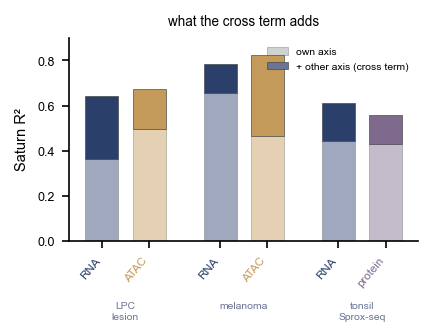

,own,cross_gain
lpc10 RNA,0.365,0.278
lpc10 ATAC,0.498,0.176
melanoma RNA,0.655,0.132
melanoma ATAC,0.466,0.356
sprox RNA,0.442,0.169
sprox Protein,0.428,0.130


In [7]:
def draw_split(keys, ax):
    x, ticks = 0, []
    for k in keys:
        for nm, m in (("RNA", "RNA"), ("X", XMOD[k])):
            f_, o_ = SUM[k][f"R2_{nm}"]["full"], SUM[k][f"R2_{nm}"]["own_only"]
            ax.bar(x, o_, 0.7, color=mcol(m), alpha=0.45, edgecolor=INK, lw=0.3)
            ax.bar(x, f_ - o_, 0.7, bottom=o_, color=mcol(m), edgecolor=INK, lw=0.3)
            ticks.append((x, XLAB.get(m, m), mcol(m))); x += 1
        ax.text(x - 1.5, -0.3, NAME[k].replace(" ", "\n", 1), transform=ax.get_xaxis_transform(), ha="center", va="top",
                fontsize=5, color=SLATE)
        x += 0.5
    ax.set_xticks([t[0] for t in ticks]); ax.set_xticklabels([t[1] for t in ticks], rotation=50, ha="right", fontsize=5.5)
    for tl, t in zip(ax.get_xticklabels(), ticks):
        tl.set_color(t[2])
    ax.set_ylabel("Saturn R²"); ax.set_ylim(0, 0.9)
    ax.legend(handles=[Patch(fc=GREY, alpha=0.45, ec=INK, lw=0.3, label="own axis"),
                       Patch(fc=SLATE, ec=INK, lw=0.3, label="+ other axis (cross term)")], fontsize=5, loc="upper right")
    ax.set_title("what the cross term adds", fontsize=6.5)


fig, ax = plt.subplots(figsize=(3.0, 2.6)); fig.subplots_adjust(bottom=0.36)
draw_split(MAIN, ax); plt.show()
pd.DataFrame({f"{k} {m}": dict(own=SUM[k][f"R2_{nm}"]["own_only"], cross_gain=SUM[k][f"R2_{nm}"]["full"] - SUM[k][f"R2_{nm}"]["own_only"])
              for k in MAIN for nm, m in (("RNA", "RNA"), ("X", XMOD[k]))}).T.round(3)

## Fig. 7c: genes the other isodepth explains beyond rho_RNA

Partial F-test, BH FDR 5%, ΔR² ≥ 0.01; counts are cross-explained/tested genes.

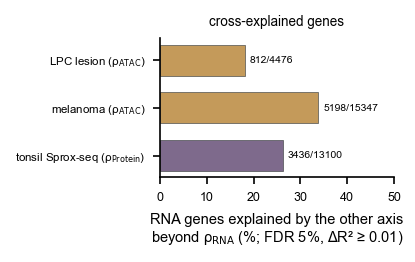

In [8]:
def draw_ngenes(keys, ax):
    for i, k in enumerate(keys):
        G = GEN[k]; hit = (G.q < 0.05) & (G.dR2_cross >= DR2_MIN)
        ax.barh(i, 100 * hit.mean(), 0.65, color=mcol(XMOD[k]), edgecolor=INK, lw=0.3)
        ax.text(100 * hit.mean() + 1, i, f"{int(hit.sum())}/{len(G)}", va="center", fontsize=5)
    ax.set_yticks(range(len(keys))); ax.set_yticklabels([f"{NAME[k]} ({sub(XMOD[k])})" for k in keys], fontsize=5.5)
    ax.invert_yaxis(); ax.set_xlim(0, 50)
    ax.set_xlabel("RNA genes explained by the other axis\nbeyond ρ$_{\\mathrm{RNA}}$ (%; FDR 5%, ΔR² ≥ 0.01)")
    ax.set_title("cross-explained genes", fontsize=6.5)


fig, ax = plt.subplots(figsize=(3.0, 1.6)); fig.subplots_adjust(left=0.38, bottom=0.3)
draw_ngenes(MAIN, ax); plt.show()

## Fig. 7d: gene profile along rho_ATAC against its own ±50 kb accessibility

For genes with q < 0.05 and an accessible window: correlation between the gene's profile along rho_ATAC and that of its own
±50 kb window (violin; black point = mean). Open points are the mean ± 2 s.d. when each gene is paired with the window of a
random other gene (200 draws); the difference is given in s.d. of this control.

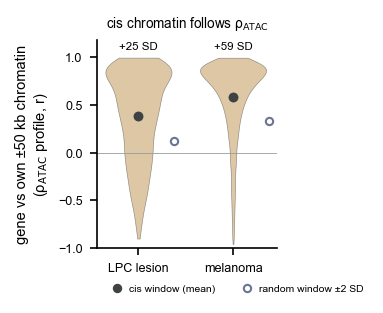

,n_genes,mean_obs,ctrl_mean,ctrl_sd,z,p
lpc10,1709.0,0.387571,0.119721,0.010619,25.223076,0.004975
melanoma,5876.0,0.586734,0.328259,0.004382,58.983972,0.004975


In [9]:
fig, ax = plt.subplots(figsize=(2.0, 2.2)); fig.subplots_adjust(left=0.3, bottom=0.25)
for i, k in enumerate(ATAC_KEYS):
    c = CIS[k].concordance.values; S = SUM[k]["cis"]
    vp = ax.violinplot(c, positions=[i], widths=0.7, showextrema=False)
    for b in vp["bodies"]:
        b.set_facecolor(mcol("ATAC")); b.set_alpha(0.55); b.set_edgecolor(INK); b.set_linewidth(0.3)
    ax.scatter(i, c.mean(), s=14, color=INK, zorder=3)
    ax.errorbar(i + 0.38, S["ctrl_mean"], yerr=2 * S["ctrl_sd"], fmt="o", mfc="white", mec=SLATE, ecolor=SLATE, ms=3.5, lw=0.7)
    ax.text(i, 1.08, f"+{S['z']:.0f} SD", ha="center", fontsize=5.5)
ax.axhline(0, color=GREY, lw=0.4); ax.set_ylim(-1, 1.18)
ax.set_xticks([0, 1]); ax.set_xticklabels([NAME[k] for k in ATAC_KEYS])
ax.set_ylabel("gene vs own ±50 kb chromatin\n(ρ$_{\\mathrm{ATAC}}$ profile, r)")
ax.legend(handles=[Line2D([], [], ls="", marker="o", color=INK, ms=3.5, label="cis window (mean)"),
                   Line2D([], [], ls="", marker="o", mfc="white", mec=SLATE, ms=3.5, label="random window ±2 SD")],
          fontsize=5, loc="upper left", bbox_to_anchor=(0.0, -0.13), ncol=2, handletextpad=0.2)
ax.set_title("cis chromatin follows ρ$_{\\mathrm{ATAC}}$", fontsize=6.5); plt.show()
pd.DataFrame({k: {m: SUM[k]["cis"][m] for m in ("n_genes", "mean_obs", "ctrl_mean", "ctrl_sd", "z", "p")} for k in ATAC_KEYS}).T

## Fig. 7e: the two isodepths and the local R² gain from the other isodepth

One row per dataset: rho_RNA, rho_X, and the local R² gain from the other isodepth in windows of the 25 nearest spots, in both
directions (one colour scale per row).

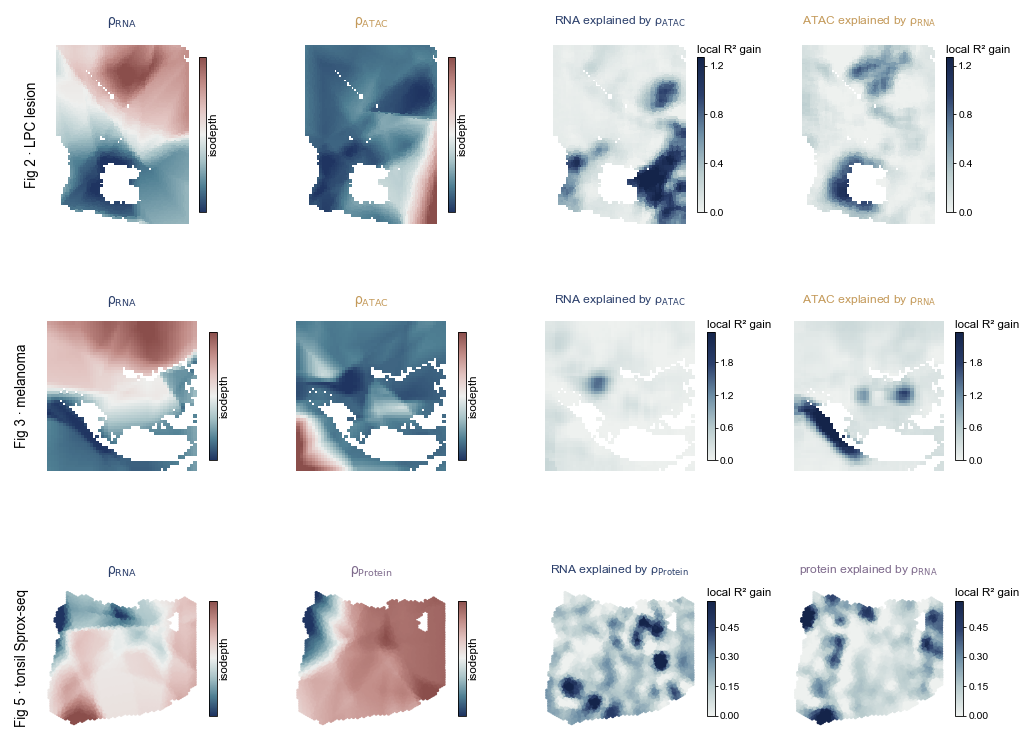

,mean_gain_RNA,mean_gain_X
lpc10,0.281,0.176
melanoma,0.133,0.354
sprox,0.170,0.131


In [10]:
def draw_gain_maps(keys, fig):
    gs = GridSpec(len(keys), 4, figure=fig, wspace=0.55, hspace=0.35, left=0.08, right=0.92, top=0.95, bottom=0.03)
    for i, k in enumerate(keys):
        T = SP[k]; xy = T[["x", "y"]].values; m = XMOD[k]; ax = [fig.add_subplot(gs[i, j]) for j in range(4)]
        for a, col, mm in ((ax[0], "rho_RNA", "RNA"), (ax[1], "rho_X", m)):
            lo, hi = np.percentile(T[col], [1, 99]); sc = smap(a, xy, T[col], CMAP["score"], lo, hi)
            cbar(fig, a, sc, "isodepth", ticks=[]); a.set_title(sub(mm), fontsize=6.5, color=mcol(mm))
        hi = max(np.percentile(T.gain_RNA, 98), np.percentile(T.gain_X, 98))
        for a, col, t, cc in ((ax[2], "gain_RNA", f"RNA explained by {sub(m)}", "RNA"),
                              (ax[3], "gain_X", f"{XLAB[m]} explained by {sub('RNA')}", m)):
            sc = smap(a, xy, T[col].clip(0, None), CMAP["recovery"], 0, hi); cbar(fig, a, sc, "local R² gain")
            a.set_title(t, fontsize=5.8, color=mcol(cc))
        ax[0].text(-0.08, 0.5, TITLE[k], transform=ax[0].transAxes, rotation=90, ha="right", va="center", fontsize=6.5)


fig = plt.figure(figsize=(7.2, 5.2)); draw_gain_maps(MAIN, fig); plt.show()
pd.DataFrame({k: dict(mean_gain_RNA=SP[k].gain_RNA.mean(), mean_gain_X=SP[k].gain_X.mean()) for k in MAIN}).T.round(3)

## Fig. 7f: example genes (Trem2, IFI44L, IGHG1)

For each gene: its expression, the part of the fit explained by the other isodepth (the B(rho_X) part) at every spot, and the
partial residual (expression minus the own-axis part, z-scored, in 25 quantile bins of rho_X) with the fitted cross profile.
For ATAC, the gene's ±50 kb window is fitted the same way and drawn in the ATAC colour.

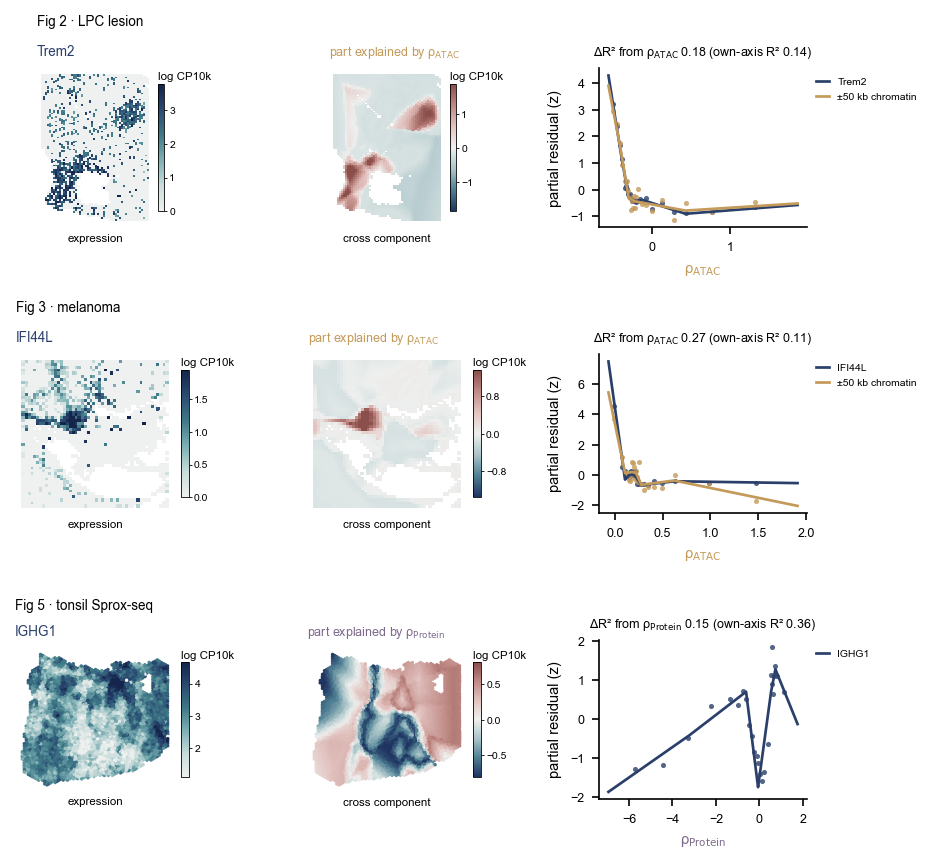

,gene,dR2_cross,R2_own,q,cis_concordance
lpc10,Trem2,0.176398,0.143665,0.0,0.997843
melanoma,IFI44L,0.267373,0.112834,0.0,0.946473
sprox,IGHG1,0.14818,0.357135,0.0,NaN


In [11]:
EX = dict(lpc10="Trem2", melanoma="IFI44L", merfish="Calb2", sprox="IGHG1", hic="NRG3")


def example_parts(k):
    """expression, own part and centred cross part of the example gene (and of its cis window for ATAC)"""
    T = SP[k]; bc = list(T.index); g = EX[k]; Xm, genes = rna_counts(k, bc)
    col = genes == g; col &= np.cumsum(col) == 1
    ys = {"gene": CT.logcpm(Xm, col)[:, 0]}
    if XMOD[k] == "ATAC":
        A, regions = atac_counts(k, bc); _, W, _ = CT.cis_windows(A, regions, np.array([g]), GTF[k], window=50_000)
        ys["cis"] = W[:, 0]
    out = {}
    for nm, v in ys.items():
        Bo, Bx = CT.hinge(T.rho_RNA.values), CT.hinge(T.rho_X.values); A = np.c_[np.ones(len(v)), Bo, Bx]
        c = np.linalg.lstsq(A, v, rcond=None)[0]; no = 1 + Bo.shape[1]; cr = Bx @ c[no:]
        out[nm] = dict(y=v, own=A[:, :no] @ c[:no], cross=cr - cr.mean())
    return out


EXP = {k: example_parts(k) for k in KEYS}


def draw_examples(keys, fig):
    gs = GridSpec(len(keys), 3, figure=fig, width_ratios=[1, 1, 1.3], wspace=0.75, hspace=0.8, left=0.05, right=0.85,
                  top=0.9, bottom=0.06)
    for i, k in enumerate(keys):
        T = SP[k]; xy = T[["x", "y"]].values; m = XMOD[k]; g = EX[k]; E = EXP[k]
        a1, a2, a3 = (fig.add_subplot(gs[i, j]) for j in range(3))
        y, cr = E["gene"]["y"], E["gene"]["cross"]
        lo, hi = np.percentile(y, [2, 99]); sc = smap(a1, xy, y, CMAP["expression"], lo, hi); cbar(fig, a1, sc, "log CP10k")
        a1.set_title(g, fontsize=6.5, color=mcol("RNA"), loc="left", fontstyle="italic")
        a1.text(0, 1.25, TITLE[k], transform=a1.transAxes, fontsize=6.5, va="bottom")
        a1.text(0.5, -0.04, "expression", transform=a1.transAxes, ha="center", va="top", fontsize=5.5)
        v = np.percentile(np.abs(cr), 99); sc = smap(a2, xy, cr, CMAP["score"], -v, v); cbar(fig, a2, sc, "log CP10k")
        a2.set_title(f"part explained by {sub(m)}", fontsize=6, color=mcol(m), loc="left")
        a2.text(0.5, -0.04, "cross component", transform=a2.transAxes, ha="center", va="top", fontsize=5.5)
        d = T.rho_X.values; nb = 25; q = np.quantile(d, np.linspace(0, 1, nb + 1)); bi = np.clip(np.digitize(d, q[1:-1]), 0, nb - 1)
        xb = np.array([d[bi == j].mean() for j in range(nb)]); o = np.argsort(d)
        for nm, lab, col in [("gene", g, mcol("RNA"))] + ([("cis", "±50 kb chromatin", mcol("ATAC"))] if "cis" in E else []):
            r = E[nm]["y"] - E[nm]["own"]; c = E[nm]["cross"]
            rb = np.array([r[bi == j].mean() for j in range(nb)]); mu, sd = rb.mean(), rb.std() + 1e-12
            a3.scatter(xb, (rb - mu) / sd, s=6, color=col, lw=0, alpha=0.8)
            a3.plot(d[o], (c[o] + r.mean() - mu) / sd, color=col, lw=1.3, label=lab)
        a3.set_xlabel(sub(m), color=mcol(m)); a3.set_ylabel("partial residual (z)")
        Gk = GEN[k].set_index("gene").loc[g]
        a3.set_title(f"ΔR² from {sub(m)} {Gk.dR2_cross:.2f} (own-axis R² {Gk.R2_own:.2f})", fontsize=6)
        a3.legend(fontsize=5, loc="upper left", bbox_to_anchor=(1.0, 1.0), handlelength=1.2)


fig = plt.figure(figsize=(6.6, 5.8)); draw_examples(MAIN, fig); plt.show()
pd.DataFrame({k: dict(gene=EX[k], **GEN[k].set_index("gene").loc[EX[k], ["dR2_cross", "R2_own", "q"]].to_dict(),
                      cis_concordance=CIS[k].set_index("gene").concordance.get(EX[k], np.nan) if k in CIS else np.nan)
              for k in MAIN}).T

## The ATAC cross term and the ATAC-steep zones (Fig. 7g to j)

The next three analyses use the two RNA+ATAC datasets. Two per-spot tables come from tools outside this environment and are
read from `published/`: cell-type composition (LPC10: cell2location proportions of 26 types in `LPC10_lesion_FOV.h5mu`,
`reproducibility/paper/scripts/lpc10_fov_h5mu.py`, env `c2l`, GPU; melanoma: Starfysh proportions of 28 states,
`starfysh_composition.csv`) and chromVAR TF activity per spot (`tf_z_per_spot.npz`, made with `saturn.tfactivity` in the
Fig. 2 and Fig. 3 notebooks).

In [12]:
def composition(key, bc):
    if key == "lpc10":
        import mudata as md
        m = md.read_h5mu(PUB / "LPC10_lesion_FOV.h5mu"); C = m.obsm["c2l_proportions"]; C.index = m.obs_names.astype(str)
    else:
        C = pd.read_csv(PUB / "starfysh_composition.csv", index_col=0); C.index = C.index.astype(str)
    return C.reindex(bc)


def tf_activity(key, bc):
    z = np.load(PUB / f"{FITS[key]['ds']}_tf_activity" / "tf_z_per_spot.npz", allow_pickle=True)
    return pd.DataFrame(z["z"], index=z["barcodes"].astype(str), columns=z["tfs"].astype(str)).reindex(bc)


COMP = {k: composition(k, list(SP[k].index)) for k in ATAC_KEYS}
TFA = {k: tf_activity(k, list(SP[k].index)) for k in ATAC_KEYS}
for k in ATAC_KEYS:
    print(k, "composition", COMP[k].shape, "TF activity", TFA[k].shape)

lpc10 composition (3425, 26) TF activity (3425, 23)
melanoma composition (1997, 28) TF activity (1997, 24)


### What switches in the steep zones

The rho_ATAC-steep zone is the top 20% of spots by the steepness ratio, the rho_RNA-steep zone the bottom 20%. For every cell
type and TF, boundary sharpness is the local gradient magnitude of the smoothed, standardised feature (8-NN smoothing, 25-NN
linear fit). Each feature gets the log2 ratio of its mean sharpness in the ATAC-steep zone over the RNA-steep zone, with a
two-sided p against 200 rotations of the zone masks.

The same step runs the checks of Supplementary Fig. 15: the steepness-gain correlation away from the edge of the section;
with log RNA depth, log ATAC depth and edge distance partialled out of the ranks; model gradients against the local
gradients of the raw Saturn targets; and, for LPC10, CODEX protein boundaries on the adjacent section (never fitted)
against each axis. The CODEX per-spot table comes from the Catalign registration (`LPC10S1_codex_per_spot.h5ad`).

In [13]:
NROT, Q = 200, 0.2
CODEX_GROUPS = {"cortical neuron layers": ["NeuN", "SATB2", "Tbr1", "Ctip2", "CUX2"], "myelin / OL": ["MBP", "Mog", "Olig2", "APC"],
                "lesion myeloid (CD11c)": ["CD11c"], "astrocyte (GFAP)": ["GFAP"]}


def gmag(v, xy):
    return np.hypot(*TR.grad_vec(v, xy, k=25).T)


def boundary(F, xy):
    """|local gradient| of each smoothed, standardised column"""
    Z = MP.smooth(((F - F.mean()) / (F.std() + 1e-12)).values, xy, k=8)
    return pd.DataFrame({c: gmag(Z[:, j], xy) for j, c in enumerate(F.columns)}, index=F.index)


def rot_p(obs, null):
    return float((1 + (np.abs(null) >= abs(obs)).sum()) / (len(null) + 1))


def edge_dist(xy):
    """distance to the edge of the section, in spot spacings (edge spots have fewer than 8 neighbours)"""
    tr = cKDTree(xy); spc = np.median(tr.query(xy, k=2)[0][:, 1])
    nb = np.array([len(v) - 1 for v in tr.query_ball_point(xy, 1.5 * spc)])
    return cKDTree(xy[nb < 8]).query(xy)[0] / spc


def steep_followup(key, rng):
    T = SP[key]; bc = list(T.index); xy = T[["x", "y"]].values
    s = CT.steepness(T); g = T.gain_RNA.values; top, bot = s >= np.quantile(s, 1 - Q), s <= np.quantile(s, Q)
    S = dict(n=len(T), n_zone=int(top.sum()))
    rows = []
    for kind, F in (("type", COMP[key]), ("TF", TFA[key])):
        F = F.loc[:, F.std() > 0].fillna(0); B = boundary(F, xy)
        con = np.log2(B[top].mean() / B[bot].mean())
        null = np.array([np.log2(B[CT.rotate(xy, top, rng)].mean() / B[CT.rotate(xy, bot, rng)].mean()).values
                         for _ in range(NROT)])
        for j, c in enumerate(F.columns):
            rows.append(dict(kind=kind, feature=c, log2_sharpness=float(con[c]), p_rot=rot_p(con[c], null[:, j])))
    pd.DataFrame(rows).sort_values("log2_sharpness", ascending=False).to_csv(OUT / f"{key}_zone_switch.csv", index=False)
    # away from the edge
    d = edge_dist(xy); S["edge"] = dict(frac_zone_within3=float((d[top] <= 3).mean()), frac_all_within3=float((d <= 3).mean()))
    for c in (0, 3, 6, 10):
        m = d > c
        if m.sum() < 30:
            continue
        obs = spearmanr(s[m], g[m]).statistic
        null = np.array([spearmanr(s[m], CT.rotate(xy[m], g[m], rng)).statistic for _ in range(NROT)])
        S["edge"][f"interior>{c}"] = dict(n=int(m.sum()), rho=float(obs), p_rot=rot_p(obs, null))
    # depth and edge partialled out
    X, _ = rna_counts(key, bc); A, _ = atac_counts(key, bc)
    cov = [np.log(np.asarray(X.sum(1)).ravel()), np.log(np.asarray(A.sum(1)).ravel()), d]

    def res(a):
        for c in cov:
            a = CT.rank_resid(a, c)
        return a
    S["controls"] = dict(rho_raw=float(spearmanr(s, g).statistic), rho_partial=float(spearmanr(res(s), res(g)).statistic))
    # model gradients vs the gradients of the raw targets
    z = dict(np.load(PUB / f"targets_{FITS[key]['ds']}.npz", allow_pickle=True))
    o = pd.Index([str(b) for b in z["barcodes"]]).get_indexer(bc)

    def gm(M):
        M = MP.smooth((M - M.mean(0)) / (M.std(0) + 1e-9), xy, k=8); return np.sqrt(sum(gmag(M[:, j], xy) ** 2 for j in range(M.shape[1])))
    gA, gR = gm(z["Y_ATAC"][o]), gm(z["Y_RNA"][o]); sd = np.log((gA / np.median(gA)) / (gR / np.median(gR)))
    S["data"] = dict(gradATAC=float(spearmanr(T.grad_X, gA).statistic), gradRNA=float(spearmanr(T.grad_RNA, gR).statistic),
                     ratio=float(spearmanr(s, sd).statistic))
    S["gain_by_quintile"] = pd.Series(g).groupby(pd.qcut(pd.Series(s).rank(method="first"), 5, labels=False).values).mean().round(4).tolist()
    # CODEX protein boundaries (LPC10)
    if key == "lpc10":
        C = ad.read_h5ad(PUB / "LPC10S1_codex_per_spot.h5ad")[bc]
        P = pd.DataFrame(np.log1p(np.asarray(C.X, float)), index=bc, columns=C.var_names)
        B = boundary(P.drop(columns="DAPI"), xy); rows = []
        for grp, cs in CODEX_GROUPS.items():
            b = B[cs].mean(1).values
            for nm, v in (("grad_RNA", np.log(T.grad_RNA.values)), ("grad_ATAC", np.log(T.grad_X.values)), ("ratio", s)):
                obs = spearmanr(v, b).statistic; null = np.array([spearmanr(v, CT.rotate(xy, b, rng)).statistic for _ in range(NROT)])
                rows.append(dict(boundary=grp, axis=nm, rho=float(obs), p_rot=rot_p(obs, null)))
        pd.DataFrame(rows).to_csv(OUT / "lpc10_codex.csv", index=False)
    return S


if not (OUT / "followup.json").exists():
    rng = np.random.default_rng(0)                    # one stream for both datasets, LPC10 first
    json.dump({k: steep_followup(k, rng) for k in ATAC_KEYS}, open(OUT / "followup.json", "w"), indent=1)
FU = json.load(open(OUT / "followup.json"))
SW = {k: pd.read_csv(OUT / f"{k}_zone_switch.csv") for k in ATAC_KEYS}
CODEX = pd.read_csv(OUT / "lpc10_codex.csv")
SW["lpc10"].head(6)

,kind,feature,log2_sharpness,p_rot
0,type,L2/3 intratelencephalic projecting glutamaterg...,1.862185,0.014925
1,type,L6 corticothalamic-projecting glutamatergic co...,1.334106,0.049751
2,type,L5 extratelencephalic projecting glutamatergic...,1.253852,0.154229
3,type,L6b glutamatergic cortical neuron,1.110414,0.034826
4,type,leptomeningeal cell,1.040658,0.164179
5,type,L6 intratelencephalic projecting glutamatergic...,1.032163,0.089552


### What absorbs the ATAC cross term

For each cross-explained gene (q < 0.05, ΔR² ≥ 0.01), `saturn.mechanism.absorption` measures the ΔR² of B(rho_ATAC) on top of
B(rho_RNA), then again with one candidate source already in the model: the gene's own ±50 kb accessibility (hinge basis),
the top 6 PCs of TF activity, the top 6 PCs of cell-type composition, all three, or a block of equal width rotated in space
(5 rotations of each block, mean). Absorbed share = 1 - ΔR² given the source / ΔR². All blocks are 15-NN smoothed. Spots
without composition or TF activity are left out. `drivers` names the cell type and TF whose profiles correlate most with
each gene's cross profile.

In [14]:
def mechanism(key):
    T = SP[key]; bc = list(T.index)
    G = GEN[key]; hit = G[(G.q < 0.05) & (G.dR2_cross >= DR2_MIN)].gene.values
    Xm, genes = rna_counts(key, bc); col = np.isin(genes, hit) & ~pd.Series(genes).duplicated().values
    names = genes[col]; Y = CT.logcpm(Xm, col)
    C, Z = COMP[key], TFA[key]; ok = C.notna().all(1).values & Z.notna().all(1).values
    T, Y, C, Z = T[ok], Y[ok], C[ok], Z[ok]; bc = list(T.index); xy = T[["x", "y"]].values
    print(f"{key}: {len(names)} cross genes, {ok.sum()}/{len(ok)} spots with composition and TF activity")
    A, regions = atac_counts(key, bc)
    keep, W, _ = CT.cis_windows(A, regions, names, GTF[key], window=50_000)
    D = MP.absorption(Y, names, T.rho_RNA.values, T.rho_X.values, xy, {"TF": Z.values, "comp": C.values}, cis=(keep, W), n_rot=5)
    D.rename(columns={"dR2_X": "dR2_ATAC"}).to_csv(OUT / f"{key}_mech_genes.csv", index=False)
    MP.drivers(Y, names, T.rho_RNA.values, T.rho_X.values, xy, {"type": C, "tf": Z}).to_csv(OUT / f"{key}_mech_drivers.csv", index=False)


for k in ATAC_KEYS:
    if not (OUT / f"{k}_mech_drivers.csv").exists():
        mechanism(k)
MECH = {k: (pd.read_csv(OUT / f"{k}_mech_genes.csv"), pd.read_csv(OUT / f"{k}_mech_drivers.csv")) for k in ATAC_KEYS}
pd.DataFrame({k: {b: np.nanmedian(MECH[k][0][f"absorbed_{b}"]) for b in ("cis", "TF", "comp", "all", "null")} | dict(n=len(MECH[k][0]))
              for k in ATAC_KEYS}).T.round(3)

,cis,TF,comp,all,null,n
lpc10,0.080,0.434,0.870,0.874,0.202,812.0
melanoma,0.187,0.183,0.595,0.698,0.148,5198.0


### Transect across the main steep zone

`saturn.transition.transect` takes the largest spatially connected part (DBSCAN, eps 1.6 spot spacings) of the top 20% of spots
by steepness, the mean local gradient of rho_ATAC in it as the direction, and a band of spots across it; s is the position
along that direction in spot spacings. Each feature (both axes, the RNA gain, composition entropy, cell types and TF
activity, all 15-NN smoothed) is binned into 18 bins along the band. The steepest change of each binned profile
([1,2,1]-smoothed) gets a 95% interval from 200 bootstrap resamples of the band spots. Sigmoid and bump fits
(`fit_sigmoid_bump`) are kept in the table; the sigmoid switch point is bootstrapped too for the axes, the entropy and every
feature with sigmoid R² > 0.5, from the same random stream.

In [15]:
NBOOT, NBIN = 200, 18


def transition(key):
    T = SP[key]; bc = list(T.index); xy = T[["x", "y"]].values
    tr = TR.transect(xy, T.rho_X.values, CT.steepness(T))
    s, band, zone = tr["s"], tr["band"], tr["zone"]
    C, Z = COMP[key], TFA[key]
    P = C.values.clip(1e-9); P = P / P.sum(1, keepdims=True); ent = -(P * np.log(P)).sum(1)
    F = pd.concat([T[["rho_X", "rho_RNA", "gain_RNA"]].set_axis(["axis:rho_ATAC", "axis:rho_RNA", "axis:RNA gain"], axis=1),
                   pd.Series(MP.smooth(ent[:, None], xy)[:, 0], index=bc, name="mix:composition entropy"),
                   pd.DataFrame(MP.smooth(C.values, xy), index=bc, columns=[f"type:{v}" for v in C.columns]),
                   pd.DataFrame(MP.smooth(Z.values, xy), index=bc, columns=[f"TF:{v}" for v in Z.columns])], axis=1)
    Fb, sb = F[band], s[band]; edges = np.linspace(sb.min(), sb.max(), NBIN + 1)
    rng = np.random.default_rng(0); rows = []
    for f in F.columns:
        y = Fb[f].values; r = TR.fit_sigmoid_bump(sb, y)
        r["steep_at"], r["steep_slope"] = TR.steepest(sb, y, edges)
        bsx = [TR.steepest(sb[i], y[i], edges)[0] for i in (rng.integers(0, len(sb), len(sb)) for _ in range(NBOOT))]
        r["steep_lo"], r["steep_hi"] = (float(v) for v in np.percentile(bsx, [2.5, 97.5]))
        r["delta_sd"] = float((np.percentile(y, 90) - np.percentile(y, 10)) / (F[f].std() + 1e-12))
        if f.split(":")[0] in ("axis", "mix") or r["R2_sig"] > 0.5:
            bs = []
            for _ in range(NBOOT):
                i = rng.integers(0, len(sb), len(sb)); b = TR.fit_sigmoid_bump(sb[i], y[i]); bs.append((b["s0"], b["w"]))
            bs = np.array(bs)
            r.update(s0_lo=float(np.nanpercentile(bs[:, 0], 2.5)), s0_hi=float(np.nanpercentile(bs[:, 0], 97.5)))
        rows.append(dict(feature=f, **r))
    pd.DataFrame(rows).to_csv(OUT / f"{key}_transition_fits.csv", index=False)
    bi = np.clip(np.digitize(sb, edges[1:-1]), 0, NBIN - 1)
    prof = Fb.groupby(bi).mean(); prof.insert(0, "s", pd.Series(sb).groupby(bi).mean().values)
    prof.insert(1, "n", pd.Series(sb).groupby(bi).size().values); prof.to_csv(OUT / f"{key}_transition_profiles.csv", index=False)
    pd.DataFrame(dict(barcode=bc, s=s, band=band, zone=zone)).to_csv(OUT / f"{key}_transition_spots.csv", index=False)
    json.dump(dict(spot_spacing=tr["spacing"], n_zone=int(zone.sum()), n_band=int(band.sum()), u=tr["u"].tolist(),
                   s_zone=[float(s[zone].min()), float(s[zone].max())]), open(OUT / f"{key}_transition_summary.json", "w"), indent=1)


for k in ATAC_KEYS:
    if not (OUT / f"{k}_transition_fits.csv").exists():
        transition(k)
TRN = {k: dict(F=pd.read_csv(OUT / f"{k}_transition_fits.csv").set_index("feature"), P=pd.read_csv(OUT / f"{k}_transition_profiles.csv"),
               sp=pd.read_csv(OUT / f"{k}_transition_spots.csv"), S=json.load(open(OUT / f"{k}_transition_summary.json")))
       for k in ATAC_KEYS}
pd.DataFrame({k: TRN[k]["S"] for k in ATAC_KEYS}).T[["n_zone", "n_band", "s_zone"]]

,n_zone,n_band,s_zone
lpc10,426,624,"[-9.945979125367773, 9.64893499059105]"
melanoma,189,338,"[-7.8793737185621175, 8.615580658753679]"


## Fig. 7g: what absorbs the ATAC cross term

Share of each gene's ΔR² from rho_ATAC absorbed by the gene's own cis chromatin, TF activity, cell-type composition, all
three, or a spatially rotated block (null), for the cross-explained genes. Black lines are the median and interquartile range;
the display is limited to -0.5 to 1.2.

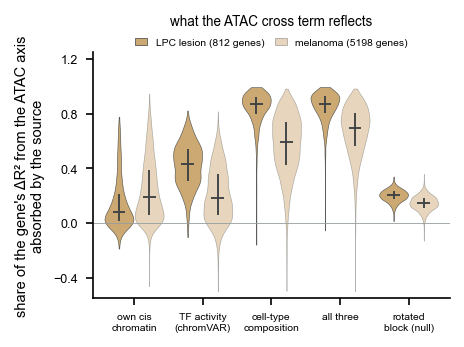

,cis,TF,comp,all,null,n
lpc10,0.080,0.434,0.870,0.874,0.202,812.0
melanoma,0.187,0.183,0.595,0.698,0.148,5198.0


In [16]:
BLOCKS = [("cis", "own cis\nchromatin"), ("TF", "TF activity\n(chromVAR)"), ("comp", "cell-type\ncomposition"),
          ("all", "all three"), ("null", "rotated\nblock (null)")]

fig, ax = plt.subplots(figsize=(3.4, 2.6)); fig.subplots_adjust(left=0.2, bottom=0.17, top=0.8)
w = 0.42
for i, k in enumerate(ATAC_KEYS):
    G = MECH[k][0]; pos = np.arange(len(BLOCKS)) + (i - 0.5) * (w + 0.02)
    data = [G[f"absorbed_{b}"].dropna().values.clip(-0.5, 1.2) for b, _ in BLOCKS]
    vp = ax.violinplot(data, positions=pos, widths=w, showextrema=False, points=200)
    for body in vp["bodies"]:
        body.set_facecolor(mcol("ATAC")); body.set_alpha(0.85 if i == 0 else 0.4); body.set_edgecolor(INK); body.set_linewidth(0.3)
    for x0, x in zip(pos, data):
        q1, q2, q3 = np.percentile(x, [25, 50, 75])
        ax.vlines(x0, q1, q3, color=INK, lw=0.9, zorder=3); ax.hlines(q2, x0 - w * 0.22, x0 + w * 0.22, color=INK, lw=0.9, zorder=3)
ax.axhline(0, color=GREY, lw=0.4); ax.set_xticks(range(len(BLOCKS))); ax.set_xticklabels([l for _, l in BLOCKS], fontsize=5)
ax.set_xlim(-0.6, len(BLOCKS) - 0.4); ax.set_ylim(-0.55, 1.25); ax.set_yticks(np.arange(-0.4, 1.21, 0.4))
ax.set_ylabel("share of the gene's ΔR² from the ATAC axis\nabsorbed by the source")
ax.legend(handles=[Patch(fc=mcol("ATAC"), alpha=0.85, ec=INK, lw=0.4, label=f"LPC lesion ({len(MECH['lpc10'][0])} genes)"),
                   Patch(fc=mcol("ATAC"), alpha=0.4, ec=INK, lw=0.4, label=f"melanoma ({len(MECH['melanoma'][0])} genes)")],
          fontsize=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, columnspacing=1.0, handlelength=1.2, borderaxespad=0.1)
ax.set_title("what the ATAC cross term reflects", fontsize=6.5, pad=13)
plt.show()
pd.DataFrame({k: {b: np.nanmedian(MECH[k][0][f"absorbed_{b}"]) for b, _ in BLOCKS} | dict(n=len(MECH[k][0])) for k in ATAC_KEYS}).T.round(3)

## Fig. 7h: the absorbed shares for three example genes per dataset

The same shares for the three genes with the largest ΔR² per dataset (from a fixed list of candidates). At the right, the cell
type and TF whose spatial profiles correlate most with the gene's cross component, with their correlation r.

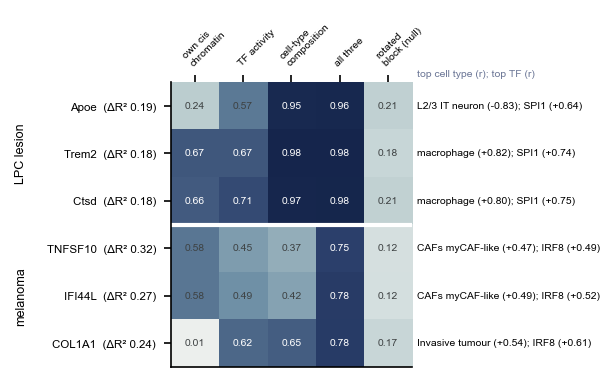

,cis,TF,comp,all,null,drivers
Apoe,0.24,0.57,0.95,0.96,0.21,L2/3 IT neuron (-0.83); SPI1 (+0.64)
Trem2,0.67,0.67,0.98,0.98,0.18,macrophage (+0.82); SPI1 (+0.74)
Ctsd,0.66,0.71,0.97,0.98,0.21,macrophage (+0.80); SPI1 (+0.75)
TNFSF10,0.58,0.45,0.37,0.75,0.12,CAFs myCAF-like (+0.47); IRF8 (+0.49)
IFI44L,0.58,0.49,0.42,0.78,0.12,CAFs myCAF-like (+0.49); IRF8 (+0.52)
COL1A1,0.01,0.62,0.65,0.78,0.17,Invasive tumour (+0.54); IRF8 (+0.61)


In [17]:
def short(f):
    """compact cell-type / TF label"""
    t = f.split(":", 1)[-1]
    for a, b in (("intratelencephalic projecting glutamatergic neuron", "IT neuron"),
                 ("corticothalamic-projecting glutamatergic cortical neuron", "CT neuron"),
                 ("extratelencephalic projecting glutamatergic cortical neuron", "ET neuron"),
                 ("glutamatergic cortical neuron", "neuron"), ("GABAergic cortical interneuron", "interneuron"),
                 ("Melanoma_NeuralCrest", "neural-crest tumour"), ("Melanoma_", ""), ("Deletional tolerance", "tolerant"),
                 ("Precursor exhaustion", "precursor-exh. T"), ("oligodendrocyte precursor cell", "OPC"), ("cell", "")):
        t = t.replace(a, b)
    t = t.strip(); t = t + " tumour" if t in ("Melanocytic", "Transitory", "Invasive") else t
    return t + (" (TF)" if f.startswith("TF:") else "")


MECH_EX = dict(lpc10=["Trem2", "C1qa", "Ctsd", "Apoe", "Ttr", "Enpp2"], melanoma=["IFI44L", "MX1", "TNFSF10", "COL1A1", "DUSP6"])
rows, lab = [], []
for k in ATAC_KEYS:
    G = MECH[k][0].set_index("gene"); dr = MECH[k][1].set_index("gene")
    for g in sorted(MECH_EX[k], key=lambda g: -G.loc[g, "dR2_ATAC"])[:3]:
        rows.append([G.loc[g, f"absorbed_{b}"] for b, _ in BLOCKS])
        t1 = dr.loc[g, "type1"].rsplit(" (", 1); f1 = dr.loc[g, "tf1"].rsplit(" (", 1)
        lab.append((g, f"{short(t1[0])} ({t1[1]}; {f1[0]} ({f1[1]}", G.loc[g, "dR2_ATAC"]))
Mx = np.array(rows, float)
fig, a2 = plt.subplots(figsize=(4.6, 2.6)); fig.subplots_adjust(left=0.25, right=0.6, top=0.78, bottom=0.05)
a2.imshow(Mx.clip(0, 1), cmap=CMAP["recovery"], vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(Mx):
    a2.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=5, color="white" if v > 0.6 else INK)
a2.xaxis.tick_top(); a2.set_xticks(range(len(BLOCKS)))
a2.set_xticklabels([l.replace("\n(chromVAR)", "") for _, l in BLOCKS], fontsize=5, rotation=45, ha="left", rotation_mode="anchor")
a2.set_yticks(range(len(lab))); a2.set_yticklabels([f"{g}  (ΔR² {d:.2f})" for g, _, d in lab], fontsize=5.5)
for tl in a2.get_yticklabels():
    tl.set_fontstyle("italic")
a2.axhline(2.5, color="white", lw=2)
for r, (g, t, _) in enumerate(lab):
    a2.text(len(BLOCKS) - 0.4, r, t, fontsize=5, va="center", ha="left")
a2.text(len(BLOCKS) - 0.4, -0.58, "top cell type (r); top TF (r)", fontsize=5, ha="left", va="bottom", color=SLATE)
for r0, r1, k in ((0, 3, "lpc10"), (3, 6, "melanoma")):
    a2.annotate(NAME[k], xy=(-0.62, (r0 + r1 - 1) / 2), xycoords=("axes fraction", "data"), rotation=90, fontsize=6,
                ha="center", va="center")
plt.show()
pd.DataFrame(Mx, index=[g for g, _, _ in lab], columns=[b for b, _ in BLOCKS]).assign(drivers=[t for _, t, _ in lab]).round(2)

## Fig. 7i, j: transect across the largest ATAC-steep zone (i, LPC lesion; j, melanoma)

Top row: the transect band (colour = position, black = steep zone, arrow = direction of the rho_ATAC gradient); rho_ATAC,
rho_RNA and the local RNA gain along the transect (z-scored); and the top switching cell type and TF, with the steep zone
shaded. Bottom row: the log steepness ratio of rho_ATAC over rho_RNA; the top switching cell type with the ATAC-steep zone in
black; and the log2 ratio of boundary sharpness between the ATAC-steep (top 20%) and RNA-steep (bottom 20%) zones, top 3 each
way with rotation P < 0.05 (* P < 0.05, ** P < 0.01). `draw_steep_case` draws one dataset; the next two cells call it.

In [18]:
ENDS = dict(lpc10=("lesion side", "cortex"), melanoma=("tumour core", "section edge"))


def top_switch(k, n=3, alpha=0.05):
    """cell types / TFs whose boundary is sharpest in the ATAC-steep zone (top n) and in the RNA-steep zone (top n)"""
    W = SW[k]; W = W[W.p_rot < alpha]
    return pd.concat([W[W.log2_sharpness > 0].nlargest(n, "log2_sharpness"), W[W.log2_sharpness < 0].nsmallest(n, "log2_sharpness")])


def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def hbar(fig, ax, sc, label):
    cax = ax.inset_axes([0.1, -0.1, 0.8, 0.05]); cb = fig.colorbar(sc, cax=cax, orientation="horizontal")
    cb.locator = MaxNLocator(nbins=3); cb.update_ticks()
    cb.outline.set_linewidth(0.4); cb.ax.tick_params(labelsize=5.5, length=1.5, width=0.4, pad=1); cb.set_label(label, fontsize=5.5, labelpad=1)


def draw_steep_case(k):
    T = SP[k]; xy = T[["x", "y"]].values; F, P, St, S = TRN[k]["F"], TRN[k]["P"], TRN[k]["sp"], TRN[k]["S"]; z0, z1 = S["s_zone"]
    Wall = top_switch(k); W = Wall[Wall.log2_sharpness > 0]
    feats = [f"type:{W[W.kind == 'type'].feature.iloc[0]}", f"TF:{W[W.kind == 'TF'].feature.iloc[0]}"] if (W.kind == "TF").any() \
        else [f"type:{f}" for f in W[W.kind == "type"].feature.iloc[:2]]
    fig = plt.figure(figsize=(3.8, 5.0)); fig.suptitle(TITLE[k], x=0.02, ha="left", fontsize=6.5)
    top = GridSpec(1, 5, figure=fig, width_ratios=[1, 0.36, 0.81, 0.36, 0.81], wspace=0, left=0.02, right=0.98, top=0.86, bottom=0.6)
    bot = GridSpec(1, 5, figure=fig, width_ratios=[1, 0.12, 1, 0.9, 0.5], wspace=0, left=0.02, right=0.98, top=0.33, bottom=0.12)
    # top row: transect
    a0 = fig.add_subplot(top[0]); ms, _ = saturn.plotting.spot_size(a0, xy)          # one marker size for the whole section
    saturn.plotting.spatial(a0, xy, np.zeros(len(xy), int), discrete=True, colors={0: MIST}, s=ms)
    b = St.band.values; zone = St.zone.values
    saturn.plotting.spatial(a0, xy[b], St.s.values[b], cmap=CMAP["pseudotime"], s=ms)
    a0.scatter(*xy[zone & b].T, s=0.5, c=INK, lw=0, rasterized=True)
    u = np.array(S["u"]); L = np.ptp(St.s.values[b]) * S["spot_spacing"]; st = xy[zone].mean(0) + u * St.s.values[b].min() * S["spot_spacing"]
    a0.annotate("", xy=st + u * L, xytext=st, arrowprops=dict(arrowstyle="-|>", lw=0.8, color=ANCHOR["rust"], mutation_scale=6))
    a0.text(0.5, -0.04, "colour = position;\nblack = steep zone", transform=a0.transAxes, ha="center", va="top", fontsize=5.5)
    a0.set_title("transect along ∂ρ$_{\\mathrm{ATAC}}$", fontsize=6, loc="left")

    def zs(f):
        return (P[f] - P[f].mean()) / (P[f].std() + 1e-12)
    a1 = fig.add_subplot(top[2])
    for f, lb, col, ls in (("axis:rho_ATAC", sub("ATAC"), mcol("ATAC"), "-"), ("axis:rho_RNA", sub("RNA"), mcol("RNA"), "-"),
                           ("axis:RNA gain", "RNA gain from " + sub("ATAC"), GREY, "--")):
        a1.plot(P.s, zs(f), ls, lw=1.3, color=col, label=lb)
    a1.set_title("both axes and the\nRNA gain", fontsize=6)
    a2 = fig.add_subplot(top[4])
    for j, f in enumerate(feats):
        col = (mcol("ATAC"), ANCHOR["teal"])[j]
        a2.plot(P.s, zs(f), "-", lw=1.2, color=col, label=short(f)); a2.scatter(P.s, zs(f), s=2.5, color=col, lw=0)
    a2.set_title("top switching\ncell type / TF", fontsize=6)
    for ax in (a1, a2):
        ax.axvspan(z0, z1, color=mcol("ATAC"), alpha=0.13, lw=0)
        ax.set_xlabel("position along\ntransect (spots)", fontsize=6); ax.set_ylabel("z (along transect)", fontsize=6)
        ax.legend(fontsize=5.5, loc="upper left", bbox_to_anchor=(-0.4, -0.45), handlelength=1.4, labelspacing=0.2, borderaxespad=0)
    y0, y1 = a1.get_ylim(); a1.set_ylim(y0 - 0.16 * (y1 - y0), y1 + 0.14 * (y1 - y0))
    a1.text(0.02, 0.97, ENDS[k][0], transform=a1.transAxes, fontsize=5.5, va="top", color=SLATE)
    a1.text(0.98, 0.03, ENDS[k][1], transform=a1.transAxes, fontsize=5.5, ha="right", va="bottom", color=SLATE)
    # bottom row: steepness ratio, top switching cell type, boundary sharpness
    lg = CT.steepness(T)
    b0, b1, b2 = fig.add_subplot(bot[0]), fig.add_subplot(bot[2]), fig.add_subplot(bot[4])
    v = np.percentile(np.abs(lg), 98); sc = smap(b0, xy, lg, CMAP["score"], -v, v); hbar(fig, b0, sc, "log steepness\nATAC / RNA")
    b0.set_title(f"{sub('ATAC')} steeper (red) /\n{sub('RNA')} steeper (blue)", fontsize=6, loc="left")
    f0 = Wall.iloc[0]; C = (COMP[k] if f0.kind == "type" else TFA[k])[f0.feature]
    sc = smap(b1, xy, C.values, CMAP["expression"] if f0.kind == "type" else CMAP["score"], np.nanpercentile(C, 2), np.nanpercentile(C, 98))
    hbar(fig, b1, sc, "proportion" if f0.kind == "type" else "activity (z)")
    zt = lg >= np.quantile(lg, 0.8); b1.scatter(*xy[zt].T, s=0.4, c=INK, lw=0, rasterized=True)
    b1.set_title(f"{short(f0.kind + ':' + f0.feature)};\nblack = {sub('ATAC')}-steep zone", fontsize=6, loc="left")
    y = np.arange(len(Wall)); b2.barh(y, Wall.log2_sharpness, 0.62, color=np.where(Wall.log2_sharpness > 0, mcol("ATAC"), mcol("RNA")))
    b2.axvline(0, color=INK, lw=0.5)
    for yy, (x, p) in enumerate(zip(Wall.log2_sharpness, Wall.p_rot)):
        b2.text(x + (0.04 if x > 0 else -0.04), yy, stars(p), ha="left" if x > 0 else "right", va="center", fontsize=5.5)
    b2.set_yticks(y); b2.set_yticklabels([short(f"{kd}:{f}") for kd, f in zip(Wall.kind, Wall.feature)], fontsize=5.5); b2.invert_yaxis()
    lim = np.abs(Wall.log2_sharpness).max() * 1.3; b2.set_xlim(-lim if (Wall.log2_sharpness < 0).any() else -0.15, lim)
    b2.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
    b2.set_xlabel(f"boundary sharpness (log2),\n{sub('ATAC')}-steep vs {sub('RNA')}-steep", fontsize=6, ha="right", x=1.0)
    b2.set_title("what switches\nin each zone", fontsize=6, loc="right")
    plt.show()
    tab = pd.DataFrame({short(f): dict(steepest_at=F.loc[f, "steep_at"], ci_lo=F.loc[f, "steep_lo"], ci_hi=F.loc[f, "steep_hi"])
                        for f in ["axis:rho_ATAC", "axis:rho_RNA", "axis:RNA gain"] + feats}).T.round(1)
    print(f"steep zone: s = {z0:.1f} to {z1:.1f}; band {S['n_band']} spots")
    return tab, Wall.assign(label=[short(f"{kd}:{f}") for kd, f in zip(Wall.kind, Wall.feature)])[["label", "log2_sharpness", "p_rot"]].round(3)

### Fig. 7i: LPC lesion

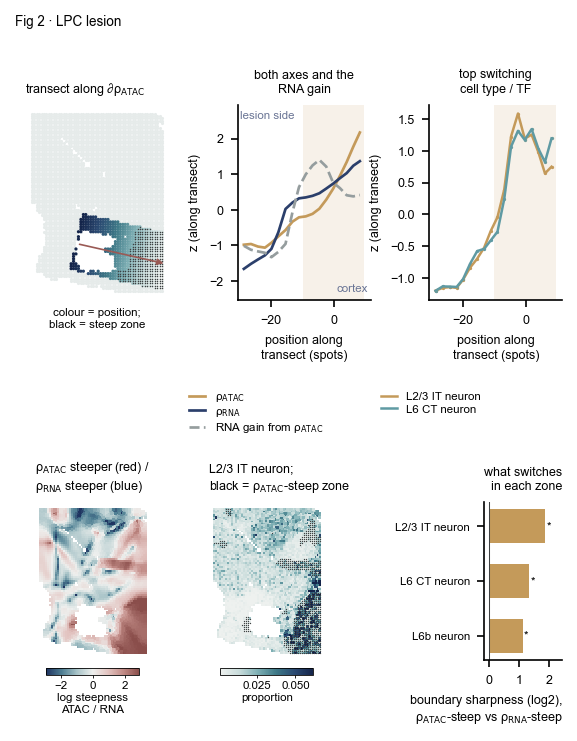

steep zone: s = -9.9 to 9.6; band 624 spots


,steepest_at,ci_lo,ci_hi
rho_ATAC,4.0,4.0,4.0
rho_RNA,-17.6,-19.8,-15.5
RNA gain,-13.3,-15.5,-11.1
L2/3 IT neuron,-6.8,-6.8,-6.8
L6 CT neuron,-6.8,-6.8,-6.8


,label,log2_sharpness,p_rot
0,L2/3 IT neuron,1.862,0.015
1,L6 CT neuron,1.334,0.050
3,L6b neuron,1.110,0.035


In [19]:
tab, sw = draw_steep_case("lpc10")
display(tab, sw)

### Fig. 7j: melanoma

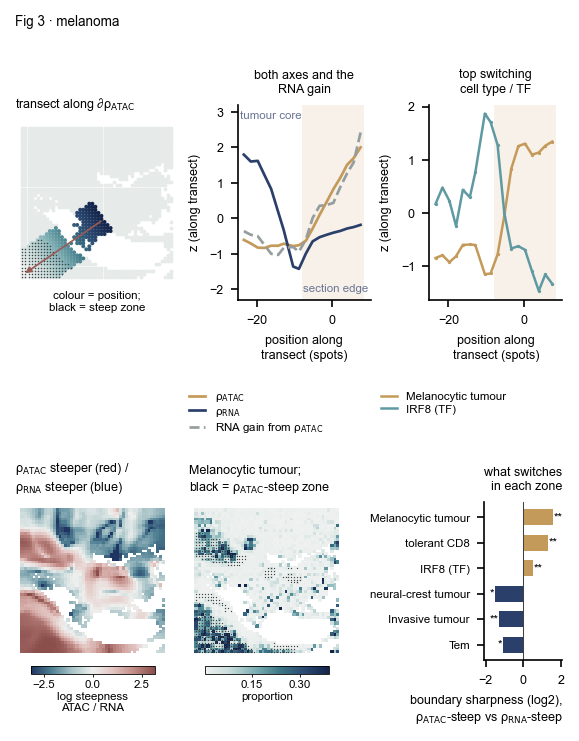

steep zone: s = -7.9 to 8.6; band 338 spots


,steepest_at,ci_lo,ci_hi
rho_ATAC,-3.3,-3.3,0.4
rho_RNA,-12.4,-14.3,-12.4
RNA gain,7.7,-6.9,7.7
Melanocytic tumour,-5.1,-5.1,-3.3
IRF8 (TF),-5.1,-12.4,-5.1


,label,log2_sharpness,p_rot
0,Melanocytic tumour,1.588,0.010
1,tolerant CD8,1.295,0.010
3,IRF8 (TF),0.492,0.005
51,neural-crest tumour,-1.486,0.020
50,Invasive tumour,-1.296,0.005
49,Tem,-1.070,0.015


In [20]:
tab, sw = draw_steep_case("melanoma")
display(tab, sw)

# Supplementary Fig. 12: the cross term in all five datasets

Supplementary Fig. 12a (Saturn against GASTON fitted to each modality alone, all five datasets) is not drawn: it needs the
GASTON baseline, as Fig. 7a.

## Supplementary Fig. 12b: own-axis part and cross-term gain of the Saturn R²

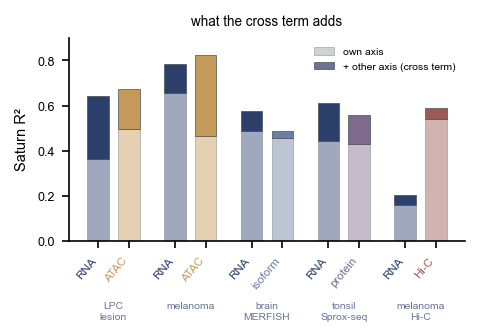

In [21]:
fig, ax = plt.subplots(figsize=(3.4, 2.6)); fig.subplots_adjust(bottom=0.36)
draw_split(KEYS, ax); plt.show()

## Supplementary Fig. 12c: RNA genes the other isodepth explains beyond rho_RNA

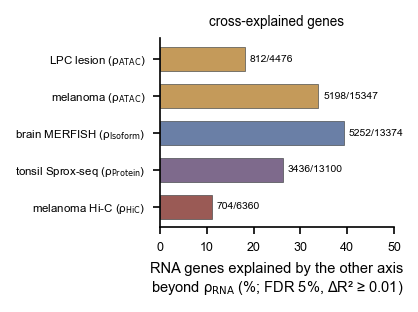

,n,tested,n_fdr_only
lpc10,812,4476,1843
melanoma,5198,15347,6980
merfish,5252,13374,8981
sprox,3436,13100,7543
hic,704,6360,4724


In [22]:
fig, ax = plt.subplots(figsize=(3.0, 2.0)); fig.subplots_adjust(left=0.38, bottom=0.25)
draw_ngenes(KEYS, ax); plt.show()
pd.DataFrame({k: dict(n=int(((GEN[k].q < 0.05) & (GEN[k].dR2_cross >= DR2_MIN)).sum()), tested=len(GEN[k]),
                      n_fdr_only=int((GEN[k].q < 0.05).sum())) for k in KEYS}).T

## Supplementary Fig. 12d: gene length of the top cross-explained genes in the Hi-C melanoma dataset

Gene body length (GENCODE v21) of the top 200 genes by cross ΔR² against all tested genes (Mann-Whitney), and the Spearman
correlation of length with the cross gain and with the own-axis R².

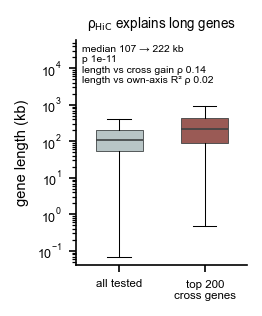

{'rho_cross': 0.1392938690436862,
 'rho_own': 0.015606516760128858,
 'median_top_kb': 221.8595,
 'median_all_kb': 106.53,
 'p': 1.180997920719785e-11}

In [23]:
Lh = GEN["hic"].assign(length=GEN["hic"].gene.map(gene_lengths(GTF["hic"]))).dropna(subset=["length"])
LS = CT.gene_length_test(Lh, dict(zip(Lh.gene, Lh.length)), 200)
Lh = Lh.assign(kb=Lh.length / 1e3); Lh = Lh[Lh.kb > 0]; top = Lh.nlargest(200, "dR2_cross").kb
fig, ax = plt.subplots(figsize=(1.9, 2.2)); fig.subplots_adjust(left=0.3, bottom=0.2)
parts = ax.boxplot([Lh.kb, top], positions=[0, 1], widths=0.55, showfliers=False, patch_artist=True,
                   medianprops=dict(color=INK, lw=0.8), whiskerprops=dict(lw=0.5), capprops=dict(lw=0.5))
for b, c in zip(parts["boxes"], (ANCHOR["silver"], mcol("HiC"))):
    b.set_facecolor(c); b.set_edgecolor(INK); b.set_linewidth(0.4)
ax.set_yscale("log"); ax.set_xticks([0, 1]); ax.set_xticklabels(["all tested", "top 200\ncross genes"], fontsize=5.5)
ax.set_ylabel("gene length (kb)")
ax.text(0.03, 0.98, f"median {LS['median_all_kb']:.0f} → {LS['median_top_kb']:.0f} kb\np {LS['p']:.0e}\n"
        f"length vs cross gain ρ {LS['rho_cross']:.2f}\nlength vs own-axis R² ρ {LS['rho_own']:.2f}",
        transform=ax.transAxes, ha="left", va="top", fontsize=5)
ax.set_ylim(top=ax.get_ylim()[1] * 40); ax.set_title("ρ$_{\\mathrm{HiC}}$ explains long genes", fontsize=6.5); plt.show()
LS

# Supplementary Fig. 13: local cross gain and example genes in the MERFISH and Hi-C melanoma datasets

## Supplementary Fig. 13a-h: the two isodepths and the local R² gain (a-d MERFISH isoform, e-h Hi-C melanoma)

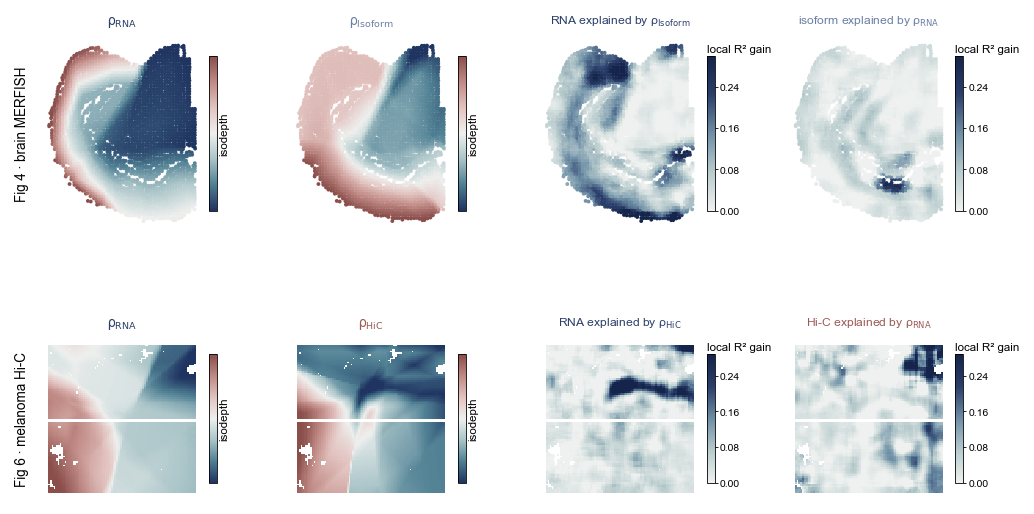

,mean_gain_RNA,mean_gain_X
merfish,0.088,0.030
hic,0.044,0.045


In [24]:
fig = plt.figure(figsize=(7.2, 3.6)); draw_gain_maps(REST, fig); plt.show()
pd.DataFrame({k: dict(mean_gain_RNA=SP[k].gain_RNA.mean(), mean_gain_X=SP[k].gain_X.mean()) for k in REST}).T.round(3)

## Supplementary Fig. 13i-n: Calb2 in the MERFISH dataset (i-k) and NRG3 in the Hi-C melanoma dataset (l-n)

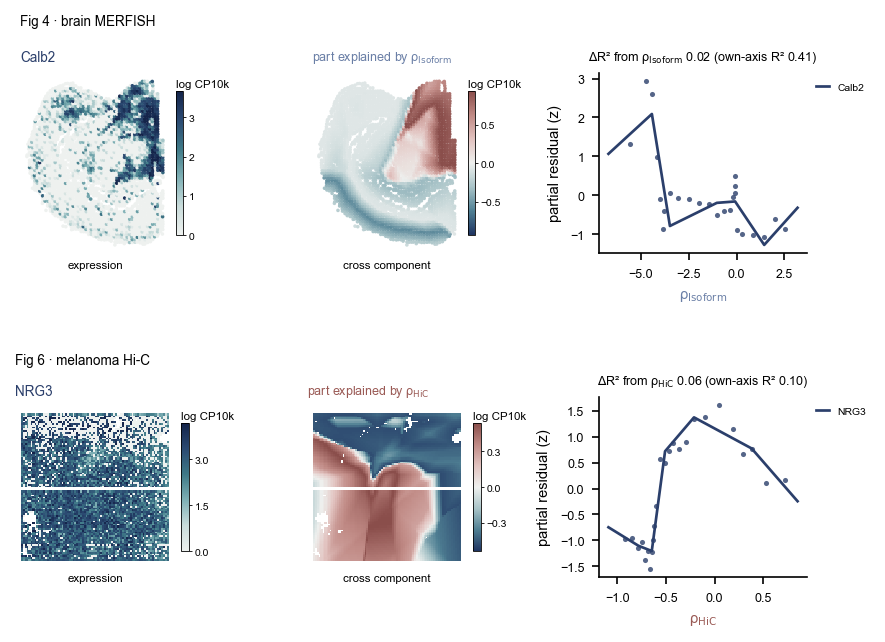

,gene,dR2_cross,R2_own,q
merfish,Calb2,0.020993,0.41132,0.0
hic,NRG3,0.057331,0.103022,0.0


In [25]:
fig = plt.figure(figsize=(6.6, 4.0)); draw_examples(REST, fig); plt.show()
pd.DataFrame({k: dict(gene=EX[k], **GEN[k].set_index("gene").loc[EX[k], ["dR2_cross", "R2_own", "q"]].to_dict()) for k in REST}).T

# Supplementary Fig. 14: direction and steepness of the isodepths against the local cross gain (a-t)

Per dataset: how far the two gradient directions differ (1 - |cos|), the steepness ratio, the local cross gain of RNA, and
each modality's gain by quintile of the steepness of the other axis, with Spearman ρ and rotation p (200 rotations).

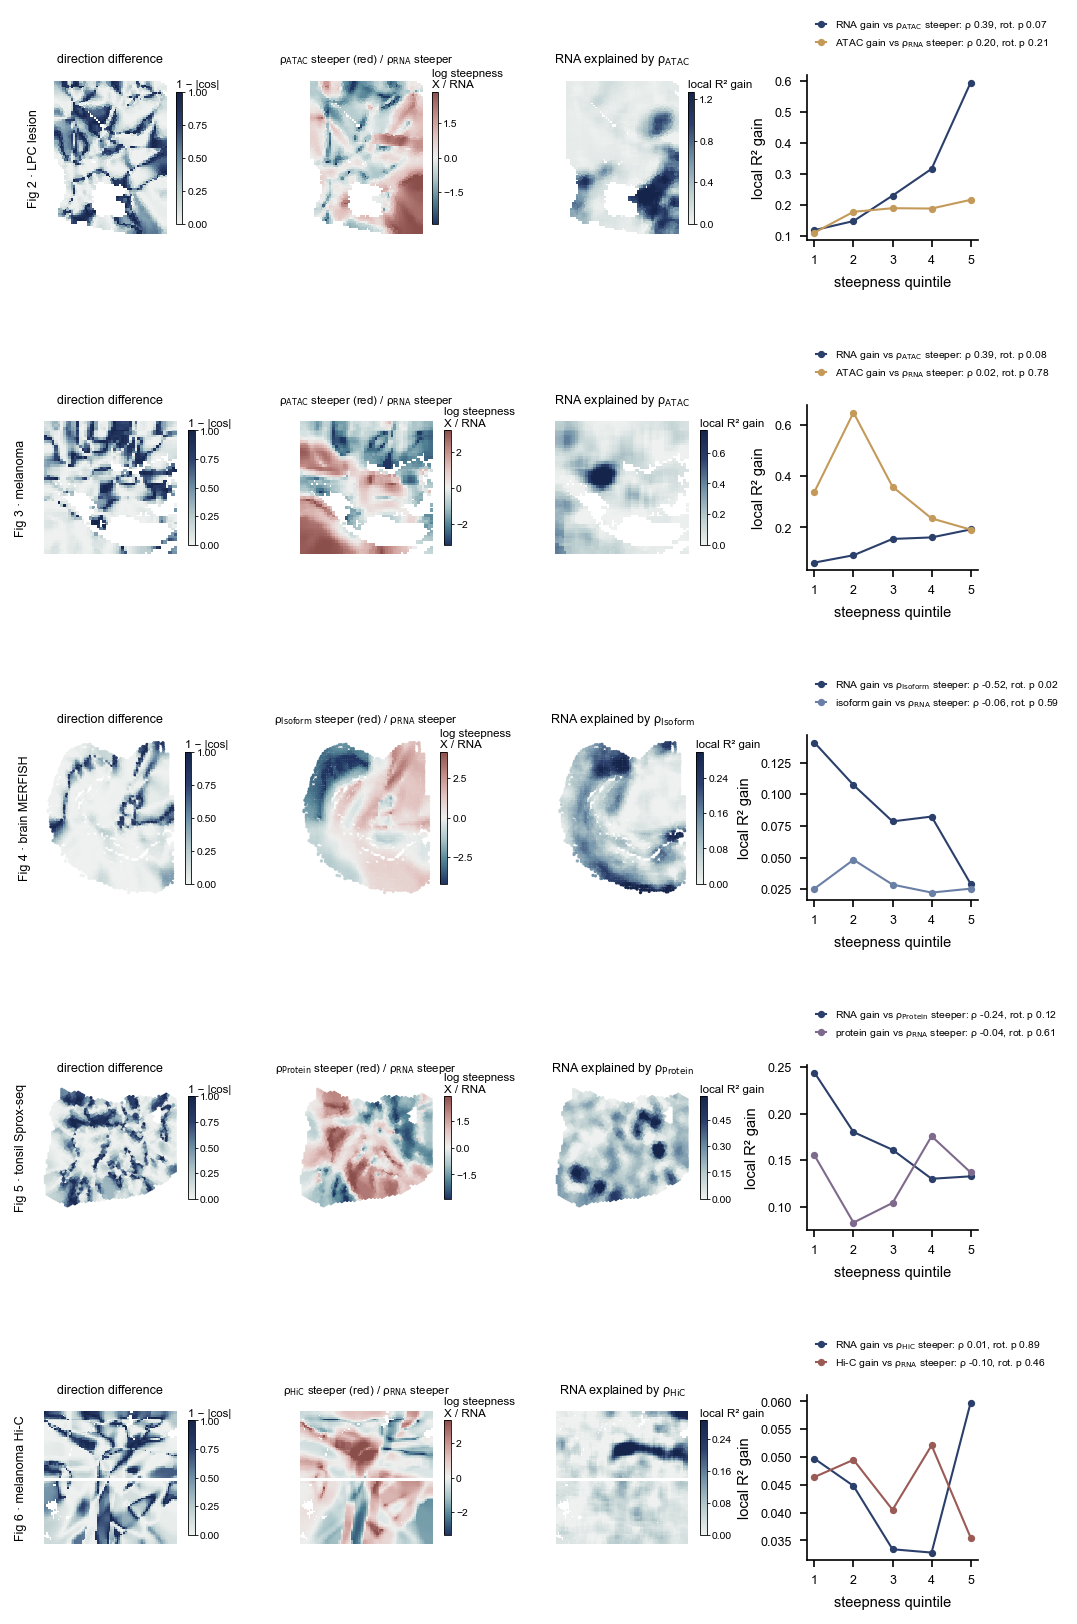

rho  p_rot
lpc10    RNA  0.393  0.075
         X    0.200  0.214
melanoma RNA  0.392  0.085
         X    0.015  0.776
merfish  RNA -0.516  0.020
         X   -0.058  0.587
sprox    RNA -0.245  0.124
         X   -0.040  0.612
hic      RNA  0.007  0.886
         X   -0.099  0.458

In [26]:
fig = plt.figure(figsize=(7.2, 11))
gs = GridSpec(len(KEYS), 4, figure=fig, hspace=1.0, wspace=0.75, width_ratios=[1, 1, 1, 1.2], left=0.08, right=0.95, top=0.94, bottom=0.04)
for i, k in enumerate(KEYS):
    T = SP[k]; xy = T[["x", "y"]].values; m = XMOD[k]; lg = CT.steepness(T)
    a0 = fig.add_subplot(gs[i, 0]); sc = smap(a0, xy, T.misalign, CMAP["recovery"], 0, 1); cbar(fig, a0, sc, "1 − |cos|")
    a0.set_title("direction difference", fontsize=6)
    a0.text(-0.08, 0.5, TITLE[k], transform=a0.transAxes, rotation=90, ha="right", va="center", fontsize=6)
    a1 = fig.add_subplot(gs[i, 1]); v = np.percentile(np.abs(lg), 98)
    sc = smap(a1, xy, lg, CMAP["score"], -v, v); cbar(fig, a1, sc, "log steepness\nX / RNA")
    a1.set_title(f"{sub(m)} steeper (red) / {sub('RNA')} steeper", fontsize=5.5)
    a2 = fig.add_subplot(gs[i, 2]); hi = max(np.percentile(T.gain_RNA, 98), 1e-3)
    sc = smap(a2, xy, T.gain_RNA.clip(0, None), CMAP["recovery"], 0, hi); cbar(fig, a2, sc, "local R² gain")
    a2.set_title(f"RNA explained by {sub(m)}", fontsize=6)
    a3 = fig.add_subplot(gs[i, 3])
    for nm, col, lb in (("RNA", mcol("RNA"), f"RNA gain vs {sub(m)} steeper"), ("X", mcol(m), f"{XLAB[m]} gain vs {sub('RNA')} steeper")):
        st = SUM[k][f"steeper_{nm}"]
        a3.plot(range(1, 6), st["gain_by_quintile"], "-o", ms=2.5, lw=1, color=col, label=f"{lb}: ρ {st['rho']:.2f}, rot. p {st['p_rot']:.2f}")
    a3.set_xticks(range(1, 6)); a3.set_xlabel("steepness quintile"); a3.set_ylabel("local R² gain")
    a3.legend(fontsize=5, loc="upper left", bbox_to_anchor=(0, 1.4), handlelength=1.0)
plt.show()
pd.DataFrame({(k, nm): dict(rho=SUM[k][f"steeper_{nm}"]["rho"], p_rot=SUM[k][f"steeper_{nm}"]["p_rot"]) for k in KEYS for nm in ("RNA", "X")}).T.round(3)

# Supplementary Fig. 15: limits of the steepness reading in the LPC lesion and melanoma datasets (a-d)

a, RNA gain by steepness quintile, with ρ, rotation p and the partial ρ (log RNA and ATAC depth and edge distance removed).
b, the same correlation keeping only spots more than n spot spacings from the edge (numbers = rotation p). c, LPC10 CODEX
protein boundary strength against |∇rho_RNA| and |∇rho_ATAC| (adjacent section, not fitted; numbers = rotation p). d, model
gradients against the gradients of the raw targets, and the steepness ratio against the ratio of the raw gradients.

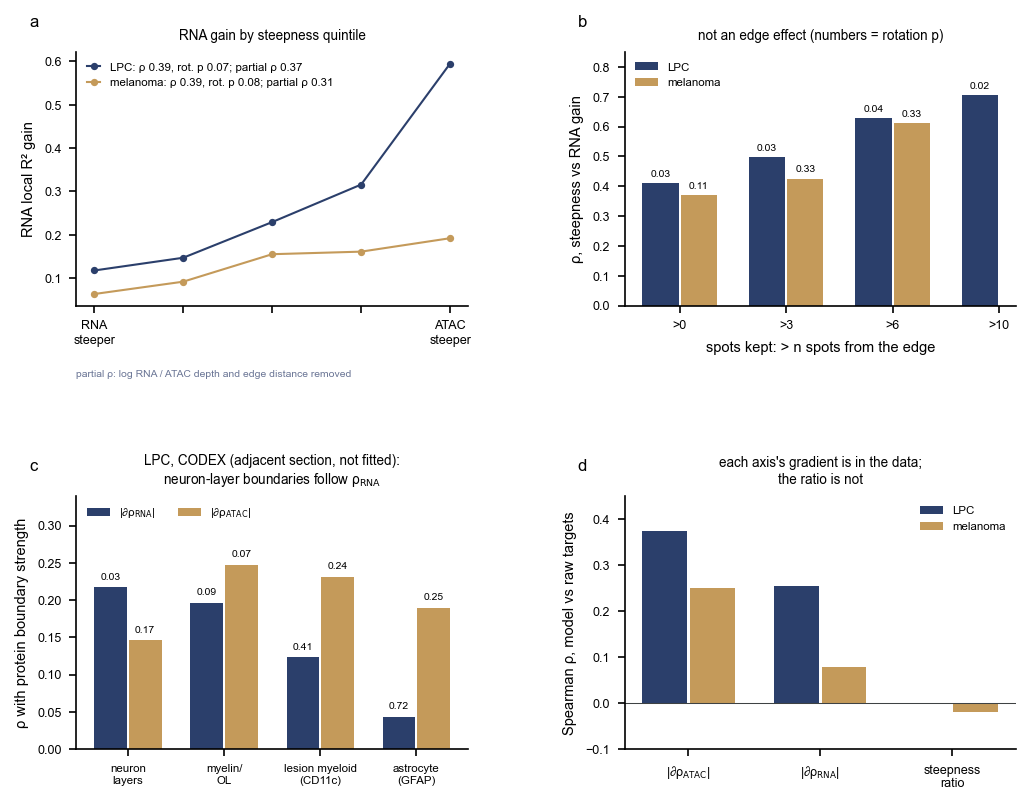

,rho_partial,data_gradATAC,data_gradRNA,data_ratio
lpc10,0.374,0.374,0.253,-0.002
melanoma,0.310,0.249,0.079,-0.019


In [27]:
NM = dict(lpc10="LPC", melanoma="melanoma"); CC = (mcol("RNA"), mcol("ATAC"))
fig = plt.figure(figsize=(7.2, 5.6))
gs = GridSpec(2, 2, figure=fig, hspace=0.75, wspace=0.4, left=0.1, right=0.97, top=0.93, bottom=0.1)
ax = fig.add_subplot(gs[0, 0])
for j, k in enumerate(ATAC_KEYS):
    St = SUM[k]["steeper_RNA"]
    ax.plot(range(1, 6), FU[k]["gain_by_quintile"], "-o", ms=2.5, lw=1, color=CC[j],
            label=f"{NM[k]}: ρ {St['rho']:.2f}, rot. p {St['p_rot']:.2f}; partial ρ {FU[k]['controls']['rho_partial']:.2f}")
ax.set_xticks(range(1, 6)); ax.set_xticklabels(["RNA\nsteeper", "", "", "", "ATAC\nsteeper"])
ax.set_ylabel("RNA local R² gain"); ax.set_title("RNA gain by steepness quintile", fontsize=6.5)
ax.legend(fontsize=5.5, loc="upper left", handlelength=1.2)
ax.text(0, -0.28, "partial ρ: log RNA / ATAC depth and edge distance removed", transform=ax.transAxes, fontsize=5, color=SLATE)
ax = fig.add_subplot(gs[0, 1]); cuts = [0, 3, 6, 10]
for j, k in enumerate(ATAC_KEYS):
    E = FU[k]["edge"]; cs = [c for c in cuts if f"interior>{c}" in E]; x = np.array([cuts.index(c) for c in cs]) + (j - 0.5) * 0.36
    r = [E[f"interior>{c}"] for c in cs]; ax.bar(x, [w["rho"] for w in r], 0.34, color=CC[j], label=NM[k])
    for xi, w in zip(x, r):
        ax.text(xi, w["rho"] + 0.015, f"{w['p_rot']:.2f}", ha="center", va="bottom", fontsize=5)
ax.set_xticks(range(4)); ax.set_xticklabels([">0", ">3", ">6", ">10"]); ax.set_ylim(0, 0.85)
ax.set_xlabel("spots kept: > n spots from the edge"); ax.set_ylabel("ρ, steepness vs RNA gain")
ax.set_title("not an edge effect (numbers = rotation p)", fontsize=6.5); ax.legend(fontsize=5.5, loc="upper left")
ax = fig.add_subplot(gs[1, 0]); grp = list(dict.fromkeys(CODEX.boundary))
for j, (a, lb) in enumerate((("grad_RNA", f"|∂{sub('RNA')}|"), ("grad_ATAC", f"|∂{sub('ATAC')}|"))):
    sb = CODEX[CODEX.axis == a].set_index("boundary").loc[grp]; x = np.arange(len(grp)) + (j - 0.5) * 0.36
    ax.bar(x, sb.rho, 0.34, color=CC[j], label=lb)
    for xi, (r, p) in zip(x, zip(sb.rho, sb.p_rot)):
        ax.text(xi, r + 0.008, f"{p:.2f}", ha="center", va="bottom", fontsize=5)
ax.set_xticks(range(len(grp)))
ax.set_xticklabels([g.replace(" (", "\n(").replace(" / ", "/\n").replace("cortical neuron layers", "neuron\nlayers") for g in grp], fontsize=5.5)
ax.set_ylim(0, 0.34); ax.set_ylabel("ρ with protein boundary strength")
ax.set_title("LPC, CODEX (adjacent section, not fitted):\nneuron-layer boundaries follow ρ$_{\\mathrm{RNA}}$", fontsize=6.5)
ax.legend(fontsize=5.5, loc="upper left", ncol=2)
ax = fig.add_subplot(gs[1, 1]); labs = [("gradATAC", f"|∂{sub('ATAC')}|"), ("gradRNA", f"|∂{sub('RNA')}|"), ("ratio", "steepness\nratio")]
for j, k in enumerate(ATAC_KEYS):
    ax.bar(np.arange(3) + (j - 0.5) * 0.36, [FU[k]["data"][a] for a, _ in labs], 0.34, color=CC[j], label=NM[k])
ax.axhline(0, color=INK, lw=0.5); ax.set_xticks(range(3)); ax.set_xticklabels([l for _, l in labs]); ax.set_ylim(-0.1, 0.45)
ax.set_ylabel("Spearman ρ, model vs raw targets")
ax.set_title("each axis's gradient is in the data;\nthe ratio is not", fontsize=6.5); ax.legend(fontsize=5.5, loc="upper right")
for a, L in zip(fig.axes, "abcd"):
    a.text(-0.12, 1.1, L, transform=a.transAxes, fontsize=8, fontweight="bold")
plt.show()
pd.DataFrame({k: dict(rho_partial=FU[k]["controls"]["rho_partial"], **{f"data_{a}": FU[k]["data"][a] for a in ("gradATAC", "gradRNA", "ratio")})
              for k in ATAC_KEYS}).T.round(3)